# Synthetic validation: the harness recovers known treatment effects

日本語要約: 実データに触れる前に、真の処置効果が分かっている合成データで
評価基盤そのものを検証する。S/T/X メタラーナーが既知の ATE（平均処置効果）を
許容誤差内で回復すること、真のアップリフト順位付けがランダムなターゲティングに
Qini 係数で勝つこと、ランダムスコアの Qini がほぼ 0 になることを assert で確認する。
この 3 点が通らない限り、実データでの比較結果は信用できない。

**What this notebook shows**

- A synthetic data generator that mimics the Criteo uplift schema but has a
  known per-row treatment effect ``tau(x)``.
- The S-, T- and X-learner implementations recover the true ATE on held-out
  data within a stated tolerance (asserted, not eyeballed).
- Ranking by the true uplift beats random targeting on the Qini coefficient,
  and a random score gives a Qini coefficient of approximately zero (both
  asserted).
- Where each learner's heterogeneity estimate is strong or weak, as a
  preview of what to expect on real data.

The point of this notebook is negative control and positive control. If the
metrics could not tell a perfect ranking from a random one, or the learners
could not find an effect we planted ourselves, notebook 02 would be
meaningless.

In [1]:
import os

import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

from uplift_bench.data import train_test_split_df
from uplift_bench.learners import SLearner, TLearner, XLearner
from uplift_bench.metrics import (
    bootstrap_ci,
    bootstrap_curve_band,
    qini_coefficient,
    qini_curve,
    uplift_by_decile,
)
from uplift_bench.plotting import plot_curves_with_bands, plot_uplift_by_decile, set_style
from uplift_bench.synthetic import FEATURES, generate, true_uplift_from_features

set_style()
SEED = 42

# Reduced sizes in CI so the notebook stays fast; full settings otherwise.
CI = bool(os.environ.get("CI"))
N_ROWS = 60_000 if CI else 200_000
N_BOOT = 100 if CI else 400
ATE_TOL = 0.008 if CI else 0.005
print(f"settings: n_rows={N_ROWS}, n_boot={N_BOOT}, ate_tolerance={ATE_TOL}")

settings: n_rows=200000, n_boot=400, ate_tolerance=0.005


## 1. Synthetic data with a known treatment effect

The generator produces the same columns as the Criteo dataset (12 numeric
features, binary `treatment`, `visit`, `conversion`, `exposure`) with:

- randomized assignment at rate 0.85, like the Criteo experiment;
- a control outcome probability $p_0(x) = \sigma(-3.2 + 0.8 f_0 - 0.5 f_2)$,
  which averages a few percent;
- a known uplift $\tau(x) = 0.04\,\sigma(2 f_1 + 0.8 f_3)$, so the effect is
  heterogeneous: rows with low $f_1$ gain almost nothing.

Because we know $\tau(x)$ for every row, we can score any estimator exactly.

In [2]:
df, truth = generate(N_ROWS, seed=SEED)
summary = pd.DataFrame(
    {
        "treated": [
            (df["treatment"] == 1).sum(),
            df.loc[df["treatment"] == 1, "visit"].mean(),
        ],
        "control": [
            (df["treatment"] == 0).sum(),
            df.loc[df["treatment"] == 0, "visit"].mean(),
        ],
    },
    index=["rows", "visit rate"],
)
true_ate = float(truth["tau"].mean())
print(summary.round(4))
print(f"\ntrue ATE (mean tau over the sample): {true_ate:.4f}")

                treated     control
rows        169861.0000  30139.0000
visit rate       0.0768      0.0555

true ATE (mean tau over the sample): 0.0201


## 2. Train/test split and the three meta-learners

All learners use the same regularized gradient boosting base model
(shallow trees, large leaves) because the outcome is rare; unregularized
trees memorize the sparse positives and their arm-difference becomes noise.
Evaluation is on held-out rows only.

- **S-learner**: one model $\mu(x, t)$;
  $\hat\tau(x) = \mu(x, 1) - \mu(x, 0)$.
- **T-learner**: per-arm models $\mu_1(x), \mu_0(x)$;
  $\hat\tau(x) = \mu_1(x) - \mu_0(x)$.
- **X-learner**: imputes per-arm effects from the T-learner stage, regresses
  them on $x$, and blends with the propensity $e$:
  $\hat\tau(x) = e\,\hat\tau_0(x) + (1 - e)\,\hat\tau_1(x)$. Assignment is
  randomized here, so the constant empirical rate is the correct propensity
  and a fitted model would only add variance.

In [3]:
train, test = train_test_split_df(df, test_size=0.5, seed=SEED)
tau_test = true_uplift_from_features(test[FEATURES])

x_train, t_train = train[FEATURES].to_numpy(), train["treatment"].to_numpy()
y_train = train["visit"].to_numpy()
x_test, t_test = test[FEATURES].to_numpy(), test["treatment"].to_numpy()
y_test = test["visit"].to_numpy()

base = HistGradientBoostingClassifier(
    random_state=SEED, max_depth=3, min_samples_leaf=500, max_iter=150
)
effect = HistGradientBoostingRegressor(
    random_state=SEED, max_depth=3, min_samples_leaf=500, max_iter=150
)
learners = {
    "S-learner": SLearner(base),
    "T-learner": TLearner(base),
    "X-learner": XLearner(base, effect, propensity="constant"),
}
scores = {}
for name, learner in learners.items():
    scores[name] = learner.fit(x_train, t_train, y_train).predict_uplift(x_test)
print("fitted:", ", ".join(scores))

fitted: S-learner, T-learner, X-learner


## 3. Validation 1: all three learners recover the true ATE

The mean of the predicted uplift over the held-out rows must match the true
ATE of those rows. This checks the scale of the estimates, which Qini-style
rank metrics cannot see.

In [4]:
rows = []
for name, score in scores.items():
    est = float(score.mean())
    rows.append(
        {
            "learner": name,
            "estimated ATE": est,
            "true ATE": tau_test.mean(),
            "error": est - tau_test.mean(),
        }
    )
ate_table = pd.DataFrame(rows).set_index("learner").round(4)
print(ate_table)

for name, score in scores.items():
    err = abs(score.mean() - tau_test.mean())
    assert err < ATE_TOL, f"{name} missed the true ATE by {err:.4f} (tol {ATE_TOL})"
print(f"\nall learners within {ATE_TOL} of the true ATE")

           estimated ATE  true ATE   error
learner                                   
S-learner         0.0171      0.02 -0.0029
T-learner         0.0209      0.02  0.0009
X-learner         0.0214      0.02  0.0014

all learners within 0.005 of the true ATE


## 4. Validation 2 and 3: the Qini metric behaves

Two controls on the metric itself, evaluated on the held-out outcomes:

- **Positive control**: ranking by the *true* $\tau(x)$ (an oracle no model
  can beat in expectation) must produce a clearly positive Qini coefficient,
  above random targeting.
- **Negative control**: a random score carries no information, so its Qini
  coefficient must be near zero and its bootstrap CI must cover zero.

In [5]:
rng = np.random.default_rng(SEED)
random_score = rng.standard_normal(len(test))

q_oracle = qini_coefficient(y_test, t_test, tau_test)
q_random = qini_coefficient(y_test, t_test, random_score)
ci_random = bootstrap_ci(qini_coefficient, y_test, t_test, random_score, n_boot=N_BOOT, seed=SEED)

print(f"Qini, oracle ranking (true tau): {q_oracle:.5f}")
print(f"Qini, random score:              {q_random:.5f}")
print(f"random-score bootstrap 95% CI:   [{ci_random['lo']:.5f}, {ci_random['hi']:.5f}]")

assert q_oracle > q_random + 0.001, "oracle ranking failed to beat random targeting"
assert abs(q_random) < 0.002, f"random score Qini too far from zero: {q_random:.5f}"
assert ci_random["lo"] < 0 < ci_random["hi"], "random-score CI does not cover zero"
print("\npositive and negative controls passed")

Qini, oracle ranking (true tau): 0.00337
Qini, random score:              0.00028
random-score bootstrap 95% CI:   [-0.00086, 0.00127]

positive and negative controls passed


## 5. Qini curves with bootstrap bands

The oracle sets the ceiling; the learners sit between it and the random
diagonal. Bands are pointwise 95% percentile bootstrap intervals.

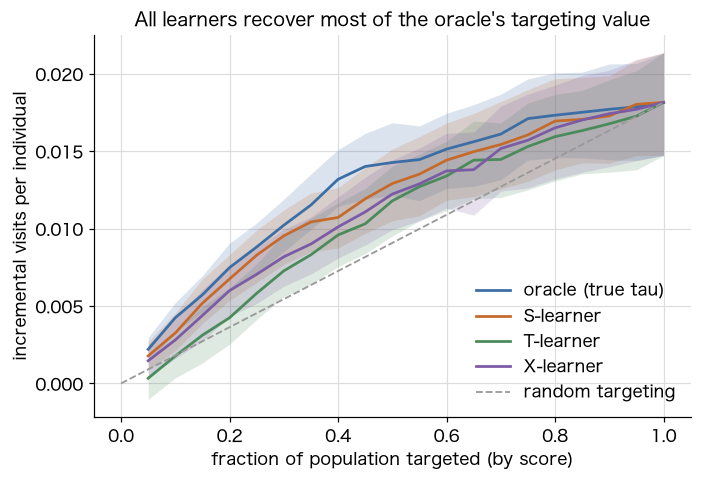

In [6]:
bands = {
    "oracle (true tau)": bootstrap_curve_band(
        qini_curve, y_test, t_test, tau_test, n_boot=N_BOOT // 2, seed=SEED
    )
}
for name, score in scores.items():
    bands[name] = bootstrap_curve_band(
        qini_curve, y_test, t_test, score, n_boot=N_BOOT // 2, seed=SEED
    )
ax = plot_curves_with_bands(
    bands,
    title="All learners recover most of the oracle's targeting value",
    ylabel="incremental visits per individual",
    diagonal_from="oracle (true tau)",
)

## 6. Where the learners differ: heterogeneity, not scale

The ATE table above showed all learners agree on the average effect. The
decile view shows how well each one *sorts* individuals, and the correlation
with the true $\tau(x)$ makes the difference explicit. Which learner sorts
best depends on the generator and the base model: on this run the S-learner
benefits from pooling both arms into one model, while the T-learner fits
the small control arm separately and picks up more noise. On real data no
oracle correlation exists, which is why notebook 02 has to rely on
Qini-style metrics with confidence intervals instead.

S-learner    0.859
T-learner    0.493
X-learner    0.703
Name: corr(predicted uplift, true tau), dtype: float64


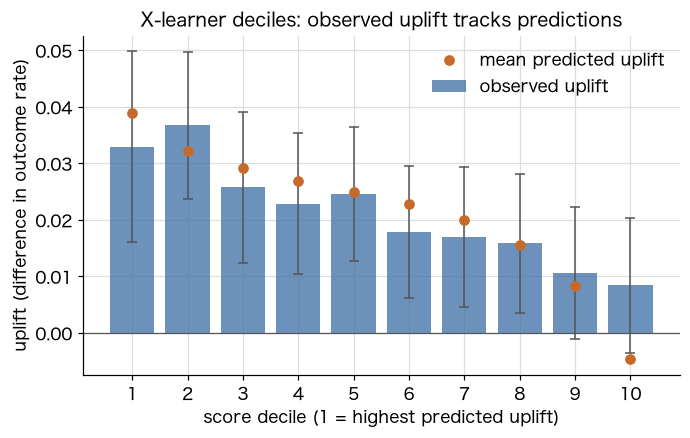

In [7]:
corr = {name: float(np.corrcoef(score, tau_test)[0, 1]) for name, score in scores.items()}
print(pd.Series(corr, name="corr(predicted uplift, true tau)").round(3))

table = uplift_by_decile(y_test, t_test, scores["X-learner"], n_bins=10)
ax = plot_uplift_by_decile(
    table,
    title="X-learner deciles: observed uplift tracks predictions",
)

## 7. Conclusions

- The three learner implementations recover a planted ATE on held-out data
  within the stated tolerance, so their scale is trustworthy.
- The Qini coefficient separates an oracle ranking from a random one and
  reports approximately zero for noise, so it is a usable comparison metric.
- Heterogeneity (per-row ranking quality) differs across learners even when
  the ATE does not; this is the axis to watch on the real data.

## Limitations

- The generator is far easier than real data: independent Gaussian
  features, a smooth logistic effect and no confounding. Passing here is
  necessary, not sufficient.
- Tolerances were set for these sample sizes; smaller samples would need
  wider ones.
- Only `visit`-like outcomes are validated; rarer outcomes (like Criteo's
  `conversion`) would need larger samples throughout.

## References

- Kunzel, Sekhon, Bickel, Yu (2019). Metalearners for estimating
  heterogeneous treatment effects using machine learning. PNAS 116(10).
- Radcliffe (2007). Using control groups to target on predicted lift.
  Direct Marketing Analytics Journal.